In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from torch import nn

In [2]:
G = nx.karate_club_graph()
d = G.degree()
d = [d[s] for s in range(len(d))]
dc = nx.betweenness_centrality(G)
dc = [x for s, x in dc.items()]
print(np.array(d).sum(), np.array(dc).sum())

156 1.4962121212121213


In [3]:
G1 = G.copy()
for i in range(34):
  G1.add_edge(34, i)
dc = nx.betweenness_centrality(G1)
d = G1.degree()
print(dc[34], d[34])

0.5902427637721753 34


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import networkx as nx
import numpy as np
import random
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

G = nx.karate_club_graph()
for i in range(34):
  G.add_edge(34, i)

In [5]:
def drawGraphWithWalk(G,walk):
 pos=nx.kamada_kawai_layout(G)
 c,k=[],0
 for u,v in G.edges:
  found=False
  for k in range(len(walk)-1):
   if (walk[k]==u and walk[k+1]==v) or (walk[k]==v and walk[k+1]==u):
    found=True
    break
  if found: c.append('red')
  else: c.append('blue')
 nx.draw(G,pos,with_labels=True,edge_color=c)
 print(walk)

[27, 24, 25, 24, 31, 28, 33]


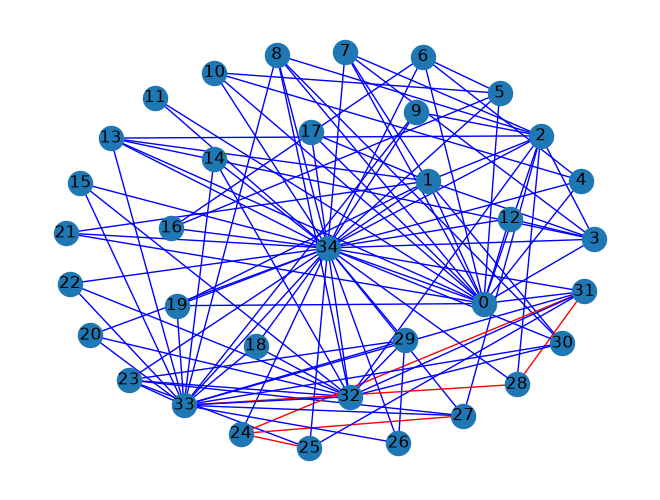

In [6]:
def generate_random_walks(G, num_walks=10, walk_length=80):
    walks = []
    nodes = list(G.nodes())
    for _ in range(num_walks):
        random.shuffle(nodes)
        node=nodes[0]
        walk = [node]
        for _ in range(walk_length - 1):
                curr = walk[-1]
                neighbors = list(G.neighbors(curr))
                if neighbors: walk.append(random.choice(neighbors))
                else: walk.append(curr)
        walks.append(walk)
    return walks

walks = generate_random_walks(G, num_walks=1, walk_length=7)
drawGraphWithWalk(G,walks[0])

In [7]:
def generate_training_pairs(nodes, walks, window_size=1, num_neg_samples=5):
    vocab_size, pairs = len(nodes), []
    for walk in walks:
        for i, center in enumerate(walk):
            start = max(0, i - window_size)
            end = min(len(walk), i + window_size + 1)
            for j in range(start, end):
                if i != j:
                    pos_ctx = walk[j]
                    pairs.append((center, pos_ctx, 1))  # Positive pair
                    for _ in range(num_neg_samples):
                        neg_ctx = random.randint(0, vocab_size - 1)
                        while neg_ctx == center or neg_ctx == pos_ctx:
                            neg_ctx = random.randint(0, vocab_size - 1)
                        pairs.append((center, neg_ctx, 0))  # Negative pair
    return window_size+num_neg_samples,pairs
batch,pairs=generate_training_pairs(list(G.nodes()), walks)

In [8]:
class GraphEmbedder(nn.Module):
    def __init__(self, num_nodes, embedding_dim):
        super(GraphEmbedder, self).__init__()
        self.embeddings = nn.Embedding(num_nodes, embedding_dim)
    def forward(self, node_ids):
        return self.embeddings(node_ids)

In [9]:
def contrastive_loss(pos_scores, neg_scores):
    loss=0
    if len(pos_scores) > 0: loss += -torch.log(torch.sigmoid(pos_scores) + 1e-15).sum()
    if len(neg_scores) > 0: loss += torch.log(torch.sigmoid(neg_scores) + 1e-15).sum()
    return loss

In [10]:
nodes=list(G.nodes())
batch_size,pairs = generate_training_pairs(nodes, walks)
walks = generate_random_walks(G, num_walks=1000, walk_length=10)
num_nodes = G.number_of_nodes()
pairs = np.array(pairs)  # (N, 3): [center, context, label]
centers = torch.tensor(pairs[:, 0], dtype=torch.long).to(device)
contexts = torch.tensor(pairs[:, 1], dtype=torch.long).to(device)
labels = torch.tensor(pairs[:, 2], dtype=torch.float).to(device)
embedding_dim,lr=3,1e-2
model = GraphEmbedder(num_nodes, embedding_dim).to(device)
optimizer = optim.SGD(model.parameters(), lr=lr)

In [11]:
model.train()
num_epochs=3
for epoch in range(num_epochs):
    total_loss = 0.0
    for i in range(0, len(pairs), batch_size):
        batch_centers = centers[i:i+batch_size]
        batch_contexts = contexts[i:i+batch_size]
        batch_labels = labels[i:i+batch_size]
        optimizer.zero_grad()
        center_embeds = model(batch_centers)  # (B, d)
        context_embeds = model(batch_contexts)  # (B, d)
        print('c:',center_embeds)
        print('ct:',context_embeds)

        scores = torch.sum(center_embeds * context_embeds, dim=1)  # (B,)
        print('c*ct:',scores)

        pos_scores = scores[batch_labels == 1]
        neg_scores = scores[batch_labels == 0]
        print('pos:',pos_scores)
        print('neg:',neg_scores)

        loss = contrastive_loss(pos_scores,neg_scores)
        print('loss:',loss)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")

c: tensor([[-1.1127, -0.3629, -0.9099],
        [-1.1127, -0.3629, -0.9099],
        [-1.1127, -0.3629, -0.9099],
        [-1.1127, -0.3629, -0.9099],
        [-1.1127, -0.3629, -0.9099],
        [-1.1127, -0.3629, -0.9099]], grad_fn=<EmbeddingBackward0>)
ct: tensor([[ 0.5754, -0.7947,  2.3593],
        [ 0.8554, -1.0324, -0.5667],
        [ 0.9518, -0.8232,  0.3989],
        [-0.7109, -0.5889, -1.6381],
        [-1.0637, -0.3322,  0.3332],
        [ 0.8572, -1.2588, -1.3362]], grad_fn=<EmbeddingBackward0>)
c*ct: tensor([-2.4985, -0.0615, -1.1232,  2.4953,  1.0009,  0.7190],
       grad_fn=<SumBackward1>)
pos: tensor([-2.4985], grad_fn=<IndexBackward0>)
neg: tensor([-0.0615, -1.1232,  2.4953,  1.0009,  0.7190], grad_fn=<IndexBackward0>)
loss: tensor(-0.3408, grad_fn=<AddBackward0>)
c: tensor([[ 0.5651, -0.7981,  2.3509],
        [ 0.5651, -0.7981,  2.3509],
        [ 0.5651, -0.7981,  2.3509],
        [ 0.5651, -0.7981,  2.3509],
        [ 0.5651, -0.7981,  2.3509],
        [ 0.5651, -

In [12]:
model.eval()
with torch.no_grad():
  embeddings = model.embeddings.weight.cpu().data.numpy()

In [13]:
print("Embedding for node 34:", embeddings[34])
print("Shape:", embeddings[34].shape)

Embedding for node 34: [-0.3776906  0.5162806 -0.8004099]
Shape: (3,)


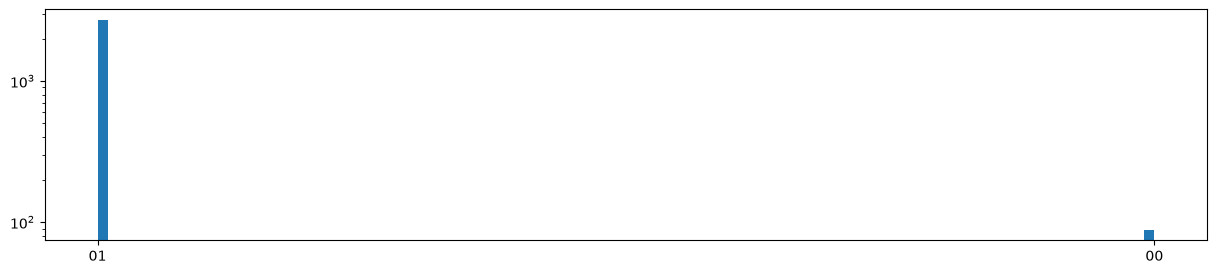

In [17]:
def next_node(G, previous, current, p, q):
  neighbors = list(G.neighbors(current))
  alphas = []
  for neighbor in neighbors:
    if neighbor == previous: alpha = 1/p
    elif G.has_edge(neighbor, previous): alpha = 1
    else: alpha = 1/q
    alphas.append(alpha)
  probs = [alpha / sum(alphas) for alpha in alphas]
  next = np.random.choice(neighbors, size=1, p=probs)[0]
  return next

def random_anonymous_walk(G, start, length, p, q):
  walk = [0]
  encoder, enc_max = {}, 0
  encoder[start] = 0
  for i in range(length):
    current = walk[-1]
    previous = walk[-1] if len(walk) > 1 else None
    next = next_node(G, previous, current, p, q)
    if next not in encoder:
      enc_max += 1
      encoder[next] = enc_max
    walk.append(encoder[next])
    return [int(x) for x in walk], encoder
walks = []
for node in G.nodes:
  for _ in range(80):
    walk, code = random_anonymous_walk(G, node, 2, 3, 2)
    walk_str = "".join([str(x) for x in walk])
    walks.append(walk_str)
plt.figure(figsize=(15, 3))
plt.hist(walks, bins = 100)
plt.yscale('log')
plt.show()

In [19]:
M = np.array([[0.5, 0.5, 0], [0.5, 0, 0], [0, 0.5, 1]])
Nm = 1/3 * np.array([[1, 1, 1], [1, 1, 1], [1, 1, 1]])
b = 0.8 
G = b * M + (1 - b) * Nm
for i in range(10):
  Gold = G.copy()
  G = G @ G
  print('\n itt: ', i, "\nres: \n", G)
  if ((np.abs(G - Gold) < 1e-10).all()):
    print('converdeg')
    break


 itt:  0 
res: 
 [[0.44       0.28       0.12      ]
 [0.25333333 0.25333333 0.09333333]
 [0.30666667 0.46666667 0.78666667]]

 itt:  1 
res: 
 [[0.30133333 0.25013333 0.17333333]
 [0.20426667 0.17866667 0.12746667]
 [0.4944     0.5712     0.6992    ]]

 itt:  2 
res: 
 [[0.22759168 0.219072   0.20530944]
 [0.16106752 0.15582464 0.14730496]
 [0.6113408  0.62510336 0.6473856 ]]

 itt:  3 
res: 
 [[0.21259739 0.2123354  0.21191149]
 [0.15180945 0.15164753 0.15138553]
 [0.63559316 0.63601707 0.63670298]]

 itt:  4 
res: 
 [[0.21212166 0.21212142 0.21212101]
 [0.15151543 0.15151528 0.15151503]
 [0.63636291 0.63636331 0.63636396]]

 itt:  5 
res: 
 [[0.21212121 0.21212121 0.21212121]
 [0.15151515 0.15151515 0.15151515]
 [0.63636364 0.63636364 0.63636364]]

 itt:  6 
res: 
 [[0.21212121 0.21212121 0.21212121]
 [0.15151515 0.15151515 0.15151515]
 [0.63636364 0.63636364 0.63636364]]
converdeg


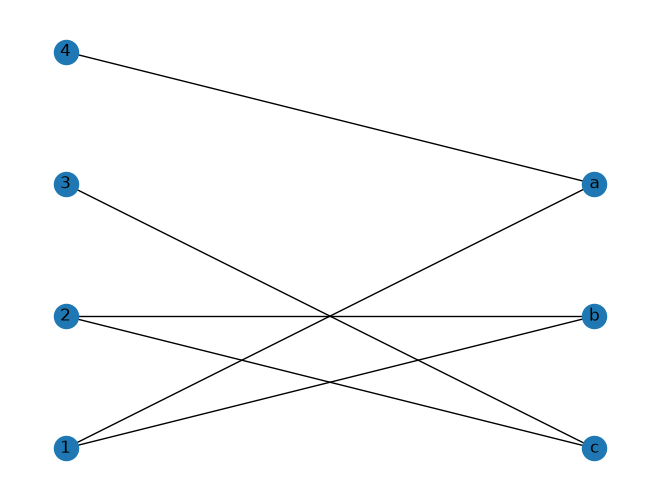

In [21]:
import networkx as nx
import matplotlib.pyplot as plt
B = nx.Graph()
B.add_nodes_from([1,2,3,4], bipartite=0) # Add the node attribute "bipartite"
B.add_nodes_from(['a','b','c'], bipartite=1)
B.add_edges_from([(1,'a'), (1,'b'), (2,'b'), (2,'c'), (3,'c'), (4,'a')])

I, r = nx.bipartite.sets(B)
pos = {}
pos.update((node, (1, index)) for index, node in enumerate(I))
pos.update((node, (2, index)) for index, node in enumerate(r))

nx.draw(B, pos = pos, with_labels=True)
plt.show()

In [26]:
M = np.array([[0.5, 0.5, 0], [0.5, 0, 0], [0, 0.5, 1]])
Nm = 1/3 * np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
# Nm = 1/3 * np.array([[1, 1, 0], [1, 1, 0], [0, 0, 1]])
b = 0.8 
G = b * M + (1 - b) * Nm
for i in range(10):
  Gold = G.copy()
  G = G @ G
  print('\n itt: ', i, "\nres: \n", G)
  if ((np.abs(G - Gold) < 1e-10).all()):
    print('converdeg')
    break


 itt:  0 
res: 
 [[0.37777778 0.21333333 0.        ]
 [0.21333333 0.16444444 0.        ]
 [0.16       0.37333333 0.75111111]]

 itt:  1 
res: 
 [[0.18822716 0.11567407 0.        ]
 [0.11567407 0.07255309 0.        ]
 [0.26026667 0.37594074 0.5641679 ]]

 itt:  2 
res: 
 [[0.04880996 0.03016551 0.        ]
 [0.03016551 0.01864444 0.        ]
 [0.23930995 0.26947547 0.31828542]]

 itt:  3 
res: 
 [[0.00329237 0.0020348  0.        ]
 [0.0020348  0.00125757 0.        ]
 [0.09597844 0.09801324 0.10130561]]

 itt:  4 
res: 
 [[1.49800968e-05 9.25820900e-06 0.00000000e+00]
 [9.25820900e-06 5.72188784e-06 0.00000000e+00]
 [1.02385881e-02 1.02478463e-02 1.02628264e-02]]

 itt:  5 
res: 
 [[3.10117735e-10 1.91663301e-10 0.00000000e+00]
 [1.91663301e-10 1.18454434e-10 0.00000000e+00]
 [1.05325105e-04 1.05325296e-04 1.05325606e-04]]

 itt:  6 
res: 
 [[1.32907831e-19 8.21415567e-20 0.00000000e+00]
 [8.21415567e-20 5.07662739e-20 0.00000000e+00]
 [1.10934834e-08 1.10934834e-08 1.10934834e-08]]

 i

In [33]:
A = np.array([[1, 1, 0.1], [1, 2, 1], [0.1, 1, 2]])
print(A)
B = np.linalg.cholesky(A) # разложение Халецкого
print(B)
print(B @ B.T)

[[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]
[[1.         0.         0.        ]
 [1.         1.         0.        ]
 [0.1        0.9        1.08627805]]
[[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]


In [ ]:
# Неотрицательная матричная факторизация
from sklearn.decomposition import NMF

model = NMF(n_components=2, init="random", random_state=0)
W = model.fit_transform(A)
HT = model.components_
B = W
print(f"A = {A}")
print(f"B = {B}")
print(f"H = {HT}")
print("B BT: \n", B @ B.T)
print("W HT\n", W @ HT)

A = [[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]
B = [[0.65246554 0.01528511]
 [0.82869932 0.4138891 ]
 [0.01636187 0.79254598]]
H = [[1.3225177  1.66911974 0.01187808]
 [0.03061237 1.28156858 2.496243  ]]
B BT: 
 [[0.42594491 0.54702409 0.02278971]
 [0.54702409 0.85804675 0.34158521]
 [0.02278971 0.34158521 0.62839684]]
W HT
 [[0.86336514 1.10863203 0.0459054 ]
 [1.10863965 1.91362566 1.04301112]
 [0.04590057 1.04301194 1.9785817 ]]


In [ ]:
# Разложение через собственные вектора
import numpy as np
from scipy.linalg import eigh

A = np.array([[0.1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])
eigenvalues, eigenvectors = eigh(A)
eigenvalues = np.maximum(eigenvalues, 0)
sqrt_eigenvalues = np.sqrt(eigenvalues)
B = eigenvectors @ np.diag(sqrt_eigenvalues)

print("A:\n", A,'\n')
print("B:\n", np.round(B,2),'\n')
print("B @ B.T:\n", B @ B.T,'\n')

A:
 [[0.1 1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]] 

B:
 [[ 0.   -0.43 -0.46]
 [ 0.   -0.59 -1.31]
 [ 0.    0.86 -1.13]] 

B @ B.T:
 [[0.39507846 0.85526229 0.14853711]
 [0.85526229 2.07099469 0.97619226]
 [0.14853711 0.97619226 2.00798381]] 



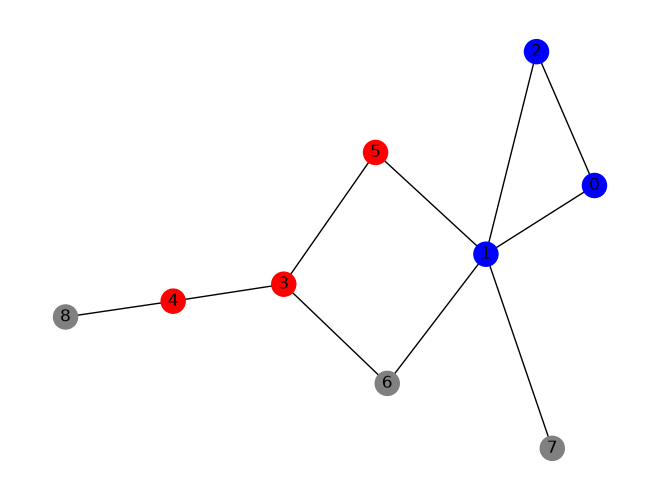

In [37]:
# Алгоритм message passen что то такое
G=nx.Graph()
G.add_nodes_from([(0,{'Y':1,'train':1}),(1,{'Y':1,'train':1}),(2,{'Y':1,'train':1}),
                  (3,{'Y':0,'train':1}),(4,{'Y':0,'train':1}),(5,{'Y':0,'train':1}),
                  (6,{'Y':-1,'train':0}),(7,{'Y':-1,'train':0}),(8,{'Y':-1,'train':0}),
                  ])
G.add_edges_from([(0,1),(0,2),(1,2),(3,4),(3,5),(3,6),(1,5),(1,6),(1,7),(4,8)])
cols={-1:'gray',0:'red',1:'blue'}
c = []
for node,attr in G.nodes.items():
    c.append(cols[attr['Y']])
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, node_color=c, with_labels=True)

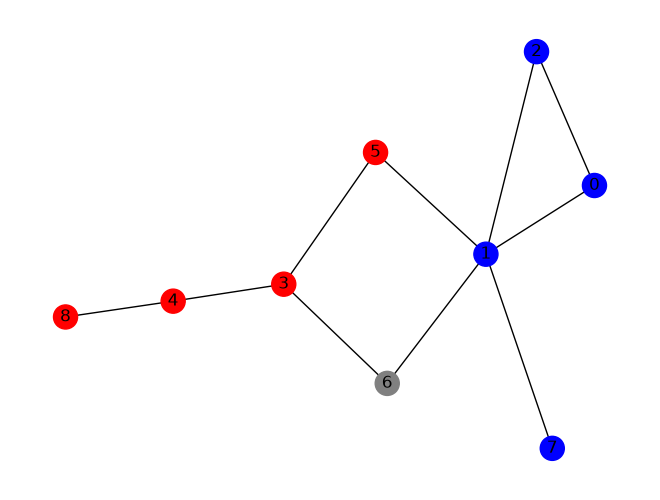

In [38]:
import random as rd
for node in G.nodes():
    if G.nodes[node]['train']==0: G.nodes[node]['Y']=0.5
for itt in range(1000):
 n=rd.choice(list(G.nodes()))
 w=[]
 for n_n in G.neighbors(n): w.append(G.nodes[n_n]['Y'])
 w=np.array(w)
 if(G.nodes[n]['train']==0): G.nodes[n]['Y']=w.mean()
c = []
for node, attr in G.nodes.items():
   if attr['Y'] > 0.5: c.append(cols[1])
   elif attr['Y'] < 0.5: c.append(cols[0])
   else:
      c.append('gray')

nx.draw(G, pos, node_color=c, with_labels=True)